<a href="https://colab.research.google.com/github/sharandeep3/Image-Captioning-/blob/main/main.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Multimodal Image Captioning + VQA (CLIP + GPT-2)

**Idea:** a frozen **CLIP vision transformer** looks at the image, a small **mapping network** turns the image embedding into a "prefix" of 10 tokens, and a **GPT-2 transformer decoder** continues from that prefix to write a caption (Stage 1) or an answer (Stage 2).

```
Image -> CLIP encoder -> 512-d embedding -> MLP bridge -> 10 prefix tokens -> GPT-2 -> text
```

**Stage 1:** captioning on Flickr8k (core project)
**Stage 2:** fine-tune the same model on a small VQA v2 subset (optional bonus)

Run on **Google Colab with a GPU** (Runtime -> Change runtime type -> T4 GPU).

## 0. Setup

In [ ]:
!pip install -q transformers datasets nltk pycocoevalcap

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 104.3/104.3 MB 8.0 MB/s eta 0:00:00


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

# Restore Flickr8k (only needed after a restart)
!unzip -q "/content/drive/MyDrive/flickr_8k.zip" -d /content/flickr8k

Mounted at /content/drive


In [ ]:
import random, json
from pathlib import Path

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from PIL import Image
from tqdm.auto import tqdm
import matplotlib.pyplot as plt
from transformers import (CLIPModel, CLIPProcessor, GPT2LMHeadModel,
                          GPT2TokenizerFast, get_linear_schedule_with_warmup)

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
device = "cuda" if torch.cuda.is_available() else "cpu"
print("Device:", device)

# ---------- paths: CHANGE THESE to where your Flickr8k lives ----------
      # Kaggle version: CSV with columns image,caption
DATA_DIR     = Path("/content/flickr8k/Flickr_Data/Flickr_Data")
IMG_DIR      = DATA_DIR / "Images"
CAPTION_FILE = DATA_DIR / "Flickr_TextData" / "Flickr8k.token.txt"
OUT_DIR = Path("/content/drive/MyDrive/captioning_outputs"); OUT_DIR.mkdir(exist_ok=True)



# ---------- hyperparameters ----------
CLIP_NAME  = "openai/clip-vit-base-patch32"
PREFIX_LEN = 10      # number of image "tokens" fed to GPT-2
EPOCHS     = 8
BATCH      = 64
MAX_LEN    = 40      # max caption length in tokens

Device: cuda


**Getting Flickr8k into Colab:** upload the zip to Google Drive, then run this (edit the zip path), or skip it if the data is already in `DATA_DIR`.

In [ ]:
# Optional: copy Flickr8k from Google Drive into Colab
# from google.colab import drive
# drive.mount('/content/drive')
# !unzip -q "/content/drive/MyDrive/flickr8k.zip" -d /content/flickr8k

## 1. Load captions and split by image

In [ ]:
rows = []
with open(CAPTION_FILE) as f:
    for line in f:
        key, cap = line.strip().split("\t")
        rows.append((key.split("#")[0], cap))
df = pd.DataFrame(rows, columns=["image", "caption"])

df["caption"] = df["caption"].str.strip().str.lower()

# Drop captions whose image file doesn't exist (Flickr8k has one bad entry)
df = df[df.image.apply(lambda n: (IMG_DIR / n).exists())].reset_index(drop=True)

print(len(df), "captions,", df.image.nunique(), "images")
df.head()

40455 captions, 8091 images


,image,caption
0,1000268201_693b08cb0e.jpg,a child in a pink dress is climbing up a set o...
1,1000268201_693b08cb0e.jpg,a girl going into a wooden building .
2,1000268201_693b08cb0e.jpg,a little girl climbing into a wooden playhouse .
3,1000268201_693b08cb0e.jpg,a little girl climbing the stairs to her playh...
4,1000268201_693b08cb0e.jpg,a little girl in a pink dress going into a woo...


In [ ]:
# Split by IMAGE (so the same photo never appears in both train and test)
images = sorted(df.image.unique())
random.Random(SEED).shuffle(images)
n = len(images)
train_imgs = set(images[:int(0.8 * n)])
val_imgs   = set(images[int(0.8 * n):int(0.9 * n)])
test_imgs  = set(images[int(0.9 * n):])

train_df = df[df.image.isin(train_imgs)].reset_index(drop=True)
val_df   = df[df.image.isin(val_imgs)].reset_index(drop=True)
test_df  = df[df.image.isin(test_imgs)].reset_index(drop=True)
print("images  train/val/test:", len(train_imgs), len(val_imgs), len(test_imgs))
print("captions train/val/test:", len(train_df), len(val_df), len(test_df))

images  train/val/test: 6472 809 810
captions train/val/test: 32360 4045 4050


## 2. Extract CLIP image features (once)

CLIP is **frozen**, so every image only needs to go through it one time. We save the embeddings and reuse them for every epoch, which makes training much faster.

In [ ]:
clip = CLIPModel.from_pretrained(CLIP_NAME).to(device).eval()
clip_proc = CLIPProcessor.from_pretrained(CLIP_NAME)

def clip_img_feats(pixel_values):
    out = clip.get_image_features(pixel_values=pixel_values)
    if not torch.is_tensor(out):          # some transformers versions return an object
        out = out.pooler_output
    return out

class ImageOnlyDS(Dataset):
    def __init__(self, names): self.names = names
    def __len__(self): return len(self.names)
    def __getitem__(self, i):
        img = Image.open(IMG_DIR / self.names[i]).convert("RGB")
        return clip_proc(images=img, return_tensors="pt")["pixel_values"][0]

feat_file = OUT_DIR / "clip_features.pt"
if feat_file.exists():
    saved = torch.load(feat_file)
    feat_of = saved
    print("Loaded cached features:", len(feat_of))
else:
    loader = DataLoader(ImageOnlyDS(images), batch_size=128, num_workers=2)
    all_feats = []
    with torch.no_grad():
        for batch in tqdm(loader):
            all_feats.append(clip_img_feats(batch.to(device)).float().cpu())
    all_feats = torch.cat(all_feats)
    feat_of = {name: all_feats[i] for i, name in enumerate(images)}
    torch.save(feat_of, feat_file)
    print("Saved features:", all_feats.shape)

config.json:   0%|          | 0.00/4.19k [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  605MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  605MB            

...

vocab.json:   0%|          | 0.00/862k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/525k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/2.22M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/389 [00:00<?, ?B/s]

Loaded cached features: 8091


## 3. Dataset and tokenizer

In [ ]:
tok = GPT2TokenizerFast.from_pretrained("gpt2")
tok.pad_token = tok.eos_token

class CaptionDS(Dataset):
    def __init__(self, d): self.items = list(zip(d.image, d.caption))
    def __len__(self): return len(self.items)
    def __getitem__(self, i):
        name, cap = self.items[i]
        return feat_of[name], cap

def caption_collate(batch):
    feats = torch.stack([b[0] for b in batch])
    enc = tok([b[1] + tok.eos_token for b in batch], padding=True, truncation=True,
              max_length=MAX_LEN, return_tensors="pt")
    labels = enc.input_ids.clone()
    labels[enc.attention_mask == 0] = -100      # ignore padding in the loss
    return feats, enc.input_ids, enc.attention_mask, labels

train_loader = DataLoader(CaptionDS(train_df), batch_size=BATCH, shuffle=True, collate_fn=caption_collate)
val_loader   = DataLoader(CaptionDS(val_df),   batch_size=BATCH, shuffle=False, collate_fn=caption_collate)

tokenizer_config.json:   0%|          | 0.00/26.0 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/1.04M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

## 4. Model: CLIP embedding -> MLP bridge -> GPT-2

The bridge maps one 512-d CLIP vector into `PREFIX_LEN` vectors of size 768 (GPT-2's embedding size). GPT-2 treats them as the beginning of the sentence and continues from there.

In [ ]:
class CaptionModel(nn.Module):
    def __init__(self, prefix_len=PREFIX_LEN, clip_dim=512):
        super().__init__()
        self.gpt = GPT2LMHeadModel.from_pretrained("gpt2")
        self.emb = self.gpt.config.n_embd
        self.prefix_len = prefix_len
        hidden = (self.emb * prefix_len) // 2
        self.mapper = nn.Sequential(
            nn.Linear(clip_dim, hidden), nn.Tanh(),
            nn.Linear(hidden, self.emb * prefix_len),
        )

    def prefix(self, feats):
        return self.mapper(feats).view(-1, self.prefix_len, self.emb)

    def forward(self, feats, input_ids, attention_mask, labels=None):
        B = feats.size(0)
        x = torch.cat([self.prefix(feats), self.gpt.transformer.wte(input_ids)], dim=1)
        ones = torch.ones(B, self.prefix_len, dtype=attention_mask.dtype, device=attention_mask.device)
        mask = torch.cat([ones, attention_mask], dim=1)
        if labels is not None:
            ignore = torch.full((B, self.prefix_len), -100, dtype=labels.dtype, device=labels.device)
            labels = torch.cat([ignore, labels], dim=1)
        return self.gpt(inputs_embeds=x, attention_mask=mask, labels=labels)

model = CaptionModel().to(device)
total = sum(p.numel() for p in model.parameters())
print(f"Parameters: {total/1e6:.1f}M (CLIP is frozen and kept outside this model)")

config.json:   0%|          | 0.00/665 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  548MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/124 [00:00<?, ?B/s]

Parameters: 155.9M (CLIP is frozen and kept outside this model)


## 5. Text generation (greedy decoding)

In [ ]:
@torch.no_grad()
def generate(model, feats, prompt="", max_new=30):
    # Generates text for a batch of image features. `prompt` is shared by the whole batch.
    model.eval()
    feats = feats.to(device)
    B = feats.size(0)
    with torch.autocast(device_type="cuda", dtype=torch.float16, enabled=(device == "cuda")):
        x = model.prefix(feats)
        if prompt:
            ids = tok(prompt, return_tensors="pt").input_ids.to(device)
            x = torch.cat([x, model.gpt.transformer.wte(ids).expand(B, -1, -1)], dim=1)
        out_ids = []
        done = torch.zeros(B, dtype=torch.bool, device=device)
        for _ in range(max_new):
            logits = model.gpt(inputs_embeds=x).logits[:, -1]
            nxt = logits.argmax(-1)
            out_ids.append(nxt)
            done |= (nxt == tok.eos_token_id)
            if done.all():
                break
            x = torch.cat([x, model.gpt.transformer.wte(nxt)[:, None]], dim=1)
    texts = []
    for seq in torch.stack(out_ids, 1).tolist():
        if tok.eos_token_id in seq:
            seq = seq[:seq.index(tok.eos_token_id)]
        texts.append(tok.decode(seq).strip())
    return texts

## 6. Train (Stage 1: captioning)

In [ ]:
opt = torch.optim.AdamW([
    {"params": model.mapper.parameters(), "lr": 5e-4},   # bridge is new, so higher LR
    {"params": model.gpt.parameters(),    "lr": 3e-5},   # GPT-2 is pre-trained, gentle fine-tuning
], weight_decay=0.01)
total_steps = EPOCHS * len(train_loader)
sched = get_linear_schedule_with_warmup(opt, int(0.05 * total_steps), total_steps)
scaler = torch.amp.GradScaler("cuda", enabled=(device == "cuda"))

def run_epoch(loader, train=True):
    model.train(train)
    losses = []
    for feats, ids, mask, labels in tqdm(loader, leave=False):
        feats, ids, mask, labels = feats.to(device), ids.to(device), mask.to(device), labels.to(device)
        with torch.set_grad_enabled(train):
            with torch.autocast(device_type="cuda", dtype=torch.float16, enabled=(device == "cuda")):
                loss = model(feats, ids, mask, labels).loss
            if train:
                opt.zero_grad()
                scaler.scale(loss).backward()
                scaler.unscale_(opt)
                torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
                scaler.step(opt); scaler.update(); sched.step()
        losses.append(loss.item())
    return float(np.mean(losses))

history, best_val = {"train": [], "val": []}, float("inf")
for epoch in range(1, EPOCHS + 1):
    tr = run_epoch(train_loader, True)
    va = run_epoch(val_loader, False)
    history["train"].append(tr); history["val"].append(va)
    print(f"Epoch {epoch}/{EPOCHS}  train loss {tr:.3f}  val loss {va:.3f}")
    if va < best_val:
        best_val = va
        torch.save(model.state_dict(), OUT_DIR / "caption_model.pt")
        print("  saved best checkpoint")

  0%|          | 0/506 [00:00<?, ?it/s]

[transformers] `loss_type=None` was set in the config but it is unrecognized. Using the default loss: `ForCausalLMLoss`.
/tmp/ipykernel_714/3333789612.py:22: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  scaler.step(opt); scaler.update(); sched.step()


  0%|          | 0/64 [00:00<?, ?it/s]

Epoch 1/8  train loss 2.696  val loss 2.267
  saved best checkpoint


  0%|          | 0/506 [00:00<?, ?it/s]

...

  0%|          | 0/64 [00:00<?, ?it/s]

Epoch 7/8  train loss 1.632  val loss 2.232


  0%|          | 0/506 [00:00<?, ?it/s]

  0%|          | 0/64 [00:00<?, ?it/s]

Epoch 8/8  train loss 1.562  val loss 2.259


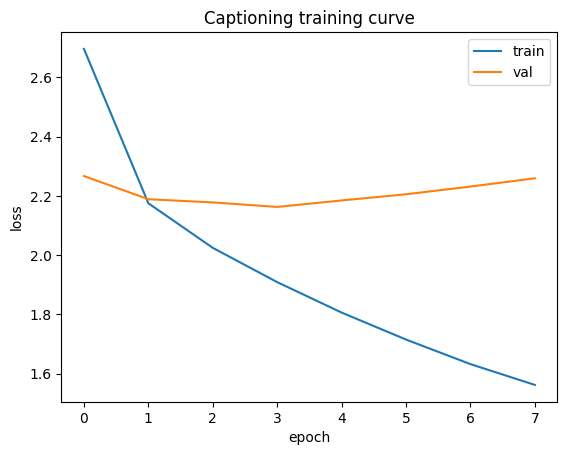

In [ ]:
plt.plot(history["train"], label="train"); plt.plot(history["val"], label="val")
plt.xlabel("epoch"); plt.ylabel("loss"); plt.legend(); plt.title("Captioning training curve")
plt.savefig(OUT_DIR / "loss_curve.png", dpi=120); plt.show()

## 7. See it work on test images

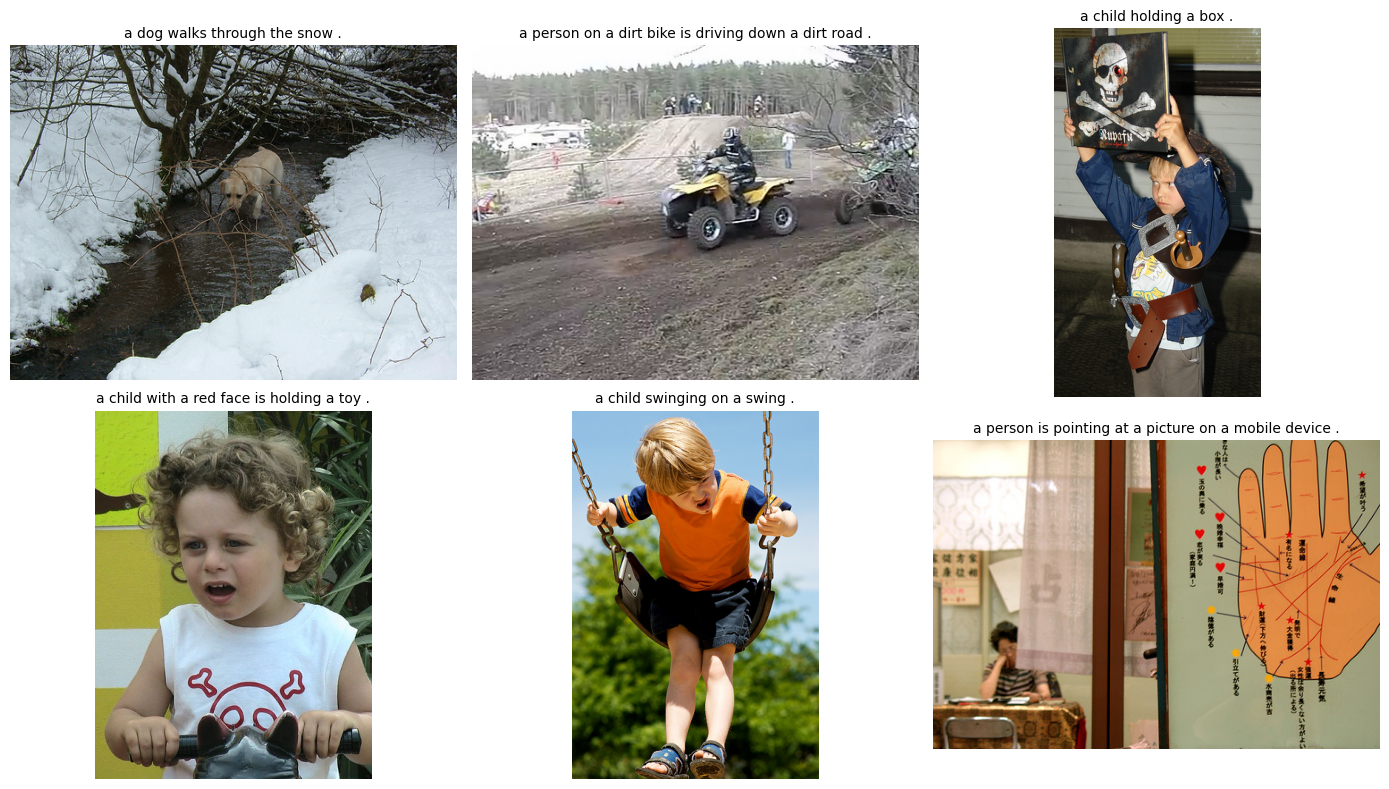

In [ ]:
model.load_state_dict(torch.load(OUT_DIR / "caption_model.pt"))
sample_names = random.Random(1).sample(sorted(test_imgs), 6)

fig, axes = plt.subplots(2, 3, figsize=(14, 8))
for ax, name in zip(axes.flat, sample_names):
    cap = generate(model, feat_of[name][None])[0]
    ax.imshow(Image.open(IMG_DIR / name)); ax.axis("off"); ax.set_title(cap, fontsize=10, wrap=True)
plt.tight_layout(); plt.savefig(OUT_DIR / "sample_captions.png", dpi=120); plt.show()

## 8. Evaluate: BLEU and CIDEr on the test set

In [ ]:
from nltk.translate.bleu_score import corpus_bleu, SmoothingFunction
from pycocoevalcap.cider.cider import Cider

test_names = sorted(test_imgs)
refs = test_df.groupby("image")["caption"].apply(list).to_dict()

hyps = {}
for i in tqdm(range(0, len(test_names), 128)):
    chunk = test_names[i:i + 128]
    caps = generate(model, torch.stack([feat_of[n] for n in chunk]))
    hyps.update(dict(zip(chunk, caps)))

smooth = SmoothingFunction().method1
list_refs = [[r.split() for r in refs[n]] for n in test_names]
list_hyps = [hyps[n].split() for n in test_names]
scores = {
    "BLEU-1": corpus_bleu(list_refs, list_hyps, weights=(1, 0, 0, 0), smoothing_function=smooth),
    "BLEU-2": corpus_bleu(list_refs, list_hyps, weights=(.5, .5, 0, 0), smoothing_function=smooth),
    "BLEU-4": corpus_bleu(list_refs, list_hyps, weights=(.25, .25, .25, .25), smoothing_function=smooth),
}
cider, _ = Cider().compute_score({n: refs[n] for n in test_names}, {n: [hyps[n]] for n in test_names})
scores["CIDEr"] = cider

for k, v in scores.items():
    print(f"{k}: {v:.3f}")
json.dump(scores, open(OUT_DIR / "caption_scores.json", "w"), indent=2)

  0%|          | 0/7 [00:00<?, ?it/s]

BLEU-1: 0.700
BLEU-2: 0.505
BLEU-4: 0.255
CIDEr: 0.680


**Stage 1 is done here.** You now have a working captioning model plus BLEU/CIDEr scores to put in your README and resume.

---
# Stage 2 (optional): Visual Question Answering

We take the same model and fine-tune it on **question -> answer** data from VQA v2. The input becomes:

```
[10 image prefix tokens] + "Question: What color is the dog? Answer:"  ->  " brown"
```

We stream a small subset from Hugging Face, so nothing big is downloaded. If the dataset name below fails, search "VQA v2" at huggingface.co/datasets and use the name you find (the field names may differ slightly).

In [ ]:
from datasets import load_dataset

N_VQA = 10000   # lower to 5000 if it's slow

vqa_stream = load_dataset("lmms-lab/VQAv2", split="validation", streaming=True)
vqa_stream = vqa_stream.shuffle(seed=SEED, buffer_size=1000)   # mix up the order a bit

vqa_samples = []   # (clip_feature, question, answer)
for ex in tqdm(vqa_stream.take(N_VQA), total=N_VQA):
    img = ex["image"].convert("RGB")
    pix = clip_proc(images=img, return_tensors="pt")["pixel_values"].to(device)
    with torch.no_grad():
        f = clip_img_feats(pix)[0].float().cpu()
    vqa_samples.append((f, ex["question"], ex["multiple_choice_answer"]))

random.Random(SEED).shuffle(vqa_samples)
cut = int(0.9 * len(vqa_samples))
vqa_train, vqa_val = vqa_samples[:cut], vqa_samples[cut:]
print(len(vqa_train), "train /", len(vqa_val), "val")
print(vqa_samples[0][1], "->", vqa_samples[0][2])

README.md:   0%|          | 0.00/962 [00:00<?, ?B/s]

Resolving data files:   0%|          | 0/68 [00:00<?, ?it/s]

Resolving data files:   0%|          | 0/36 [00:00<?, ?it/s]

Resolving data files:   0%|          | 0/143 [00:00<?, ?it/s]

Resolving data files:   0%|          | 0/68 [00:00<?, ?it/s]

Resolving data files:   0%|          | 0/36 [00:00<?, ?it/s]

Resolving data files:   0%|          | 0/143 [00:00<?, ?it/s]

  0%|          | 0/10000 [00:00<?, ?it/s]

9000 train / 1000 val
What color are the tiles on the wall? -> blue


In [ ]:
def make_prompt(q):
    return f"Question: {q} Answer:"

def vqa_collate(batch):
    feats = torch.stack([b[0] for b in batch])
    prompts = [make_prompt(b[1]) for b in batch]
    fulls = [p + " " + b[2] + tok.eos_token for p, b in zip(prompts, batch)]
    enc = tok(fulls, padding=True, truncation=True, max_length=60, return_tensors="pt")
    labels = enc.input_ids.clone()
    labels[enc.attention_mask == 0] = -100
    for i, p in enumerate(prompts):                 # only learn the ANSWER, not the question
        labels[i, :len(tok(p).input_ids)] = -100
    return feats, enc.input_ids, enc.attention_mask, labels

vqa_train_loader = DataLoader(vqa_train, batch_size=BATCH, shuffle=True, collate_fn=vqa_collate)
vqa_val_loader   = DataLoader(vqa_val,   batch_size=BATCH, shuffle=False, collate_fn=vqa_collate)

In [ ]:
# Continue from the captioning weights (this is the fine-tuning step)
model.load_state_dict(torch.load(OUT_DIR / "caption_model.pt"))

VQA_EPOCHS = 5
opt = torch.optim.AdamW([
    {"params": model.mapper.parameters(), "lr": 1e-4},
    {"params": model.gpt.parameters(),    "lr": 2e-5},
], weight_decay=0.01)
total_steps = VQA_EPOCHS * len(vqa_train_loader)
sched = get_linear_schedule_with_warmup(opt, int(0.05 * total_steps), total_steps)

best_val = float("inf")
for epoch in range(1, VQA_EPOCHS + 1):
    tr = run_epoch(vqa_train_loader, True)
    va = run_epoch(vqa_val_loader, False)
    print(f"VQA epoch {epoch}/{VQA_EPOCHS}  train loss {tr:.3f}  val loss {va:.3f}")
    if va < best_val:
        best_val = va
        torch.save(model.state_dict(), OUT_DIR / "vqa_model.pt")
        print("  saved best checkpoint")

  0%|          | 0/141 [00:00<?, ?it/s]

/tmp/ipykernel_714/3333789612.py:22: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  scaler.step(opt); scaler.update(); sched.step()


  0%|          | 0/16 [00:00<?, ?it/s]

VQA epoch 1/5  train loss 1.847  val loss 1.424
  saved best checkpoint


  0%|          | 0/141 [00:00<?, ?it/s]

...

  0%|          | 0/16 [00:00<?, ?it/s]

VQA epoch 4/5  train loss 0.970  val loss 1.393


  0%|          | 0/141 [00:00<?, ?it/s]

  0%|          | 0/16 [00:00<?, ?it/s]

VQA epoch 5/5  train loss 0.881  val loss 1.421


In [ ]:
# VQA accuracy (simple exact match against the most common human answer)
model.load_state_dict(torch.load(OUT_DIR / "vqa_model.pt"))
correct = 0
for feat, q, ans in tqdm(vqa_val[:500]):
    pred = generate(model, feat[None], prompt=make_prompt(q), max_new=6)[0]
    correct += int(pred.strip().lower() == ans.strip().lower())
vqa_acc = correct / len(vqa_val[:500])
print(f"VQA exact-match accuracy on {len(vqa_val[:500])} val questions: {vqa_acc:.1%}")
json.dump({"vqa_exact_match": vqa_acc}, open(OUT_DIR / "vqa_scores.json", "w"))

  0%|          | 0/500 [00:00<?, ?it/s]

VQA exact-match accuracy on 500 val questions: 37.2%


## 9. Ask your own questions

`caption_image` and `ask` take an image path and give you text back. This is the "how do I ask the question" part: you just change the string and run the cell.

Note: `vqa_model.pt` is the question-answering version. Use `caption_model.pt` if you want the original captioner (the VQA fine-tune can make captions worse).

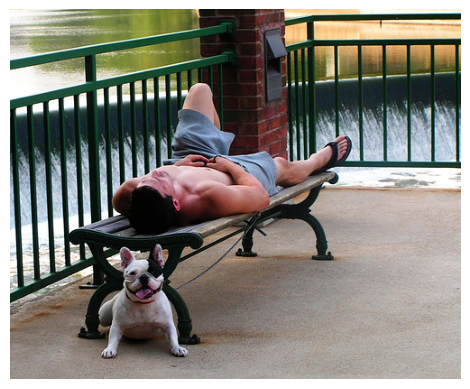

Q: What is in the picture?  A: dog
Q: How many people are there? A: 1
Q: What color is it? A: brown


In [ ]:
def image_feature(path):
    img = Image.open(path).convert("RGB")
    pix = clip_proc(images=img, return_tensors="pt")["pixel_values"].to(device)
    with torch.no_grad():
        return clip_img_feats(pix)[0].float().cpu()[None]

def ask(path, question):
    return generate(model, image_feature(path), prompt=make_prompt(question), max_new=6)[0]

def caption_image(path, caption_weights=OUT_DIR / "caption_model.pt"):
    model.load_state_dict(torch.load(caption_weights))
    return generate(model, image_feature(path))[0]

# ---- try it ----
test_path = IMG_DIR / sorted(test_imgs)[0]
plt.imshow(Image.open(test_path)); plt.axis("off"); plt.show()

model.load_state_dict(torch.load(OUT_DIR / "vqa_model.pt"))
print("Q: What is in the picture?  A:", ask(test_path, "What is in the picture?"))
print("Q: How many people are there? A:", ask(test_path, "How many people are there?"))
print("Q: What color is it? A:", ask(test_path, "What color is it?"))

## Resume line

> Built a multimodal system combining a frozen CLIP vision transformer with a GPT-2 decoder via a learned prefix-mapping network. Trained for image captioning on Flickr8k (BLEU-4 / CIDEr reported above) and fine-tuned for visual question answering on a VQA v2 subset.

Fill in your real scores from `outputs/caption_scores.json` and `outputs/vqa_scores.json`.